<a href="https://colab.research.google.com/github/Makande340/A04-clustering/blob/main/notebook(6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Mofeoluwa Akande

**Date:** [To be provided]

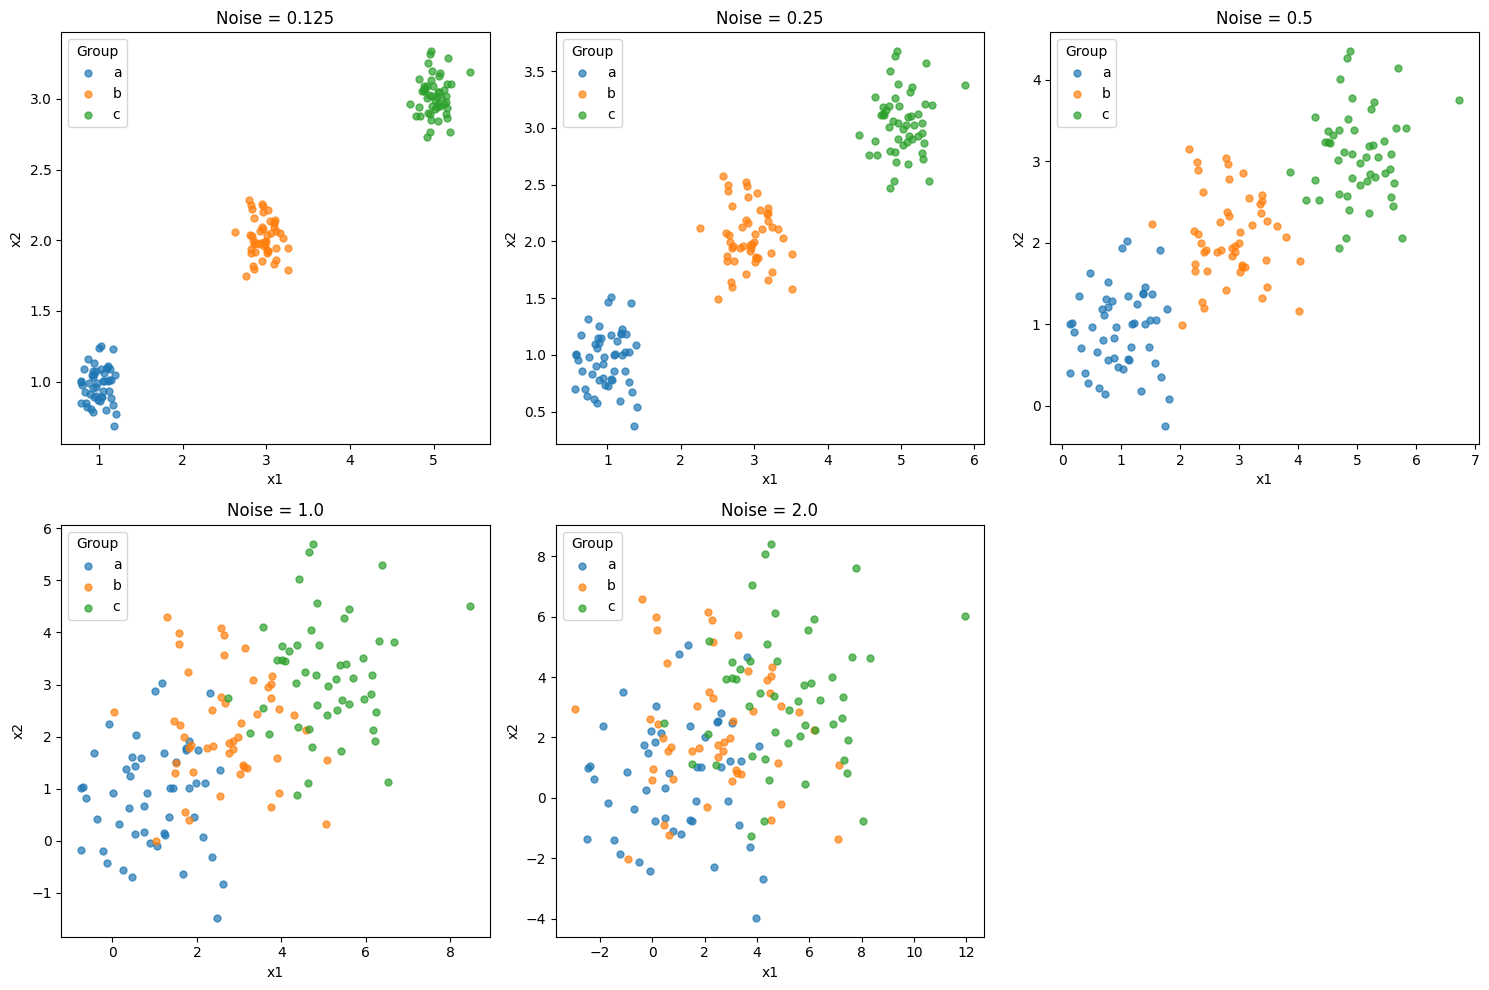

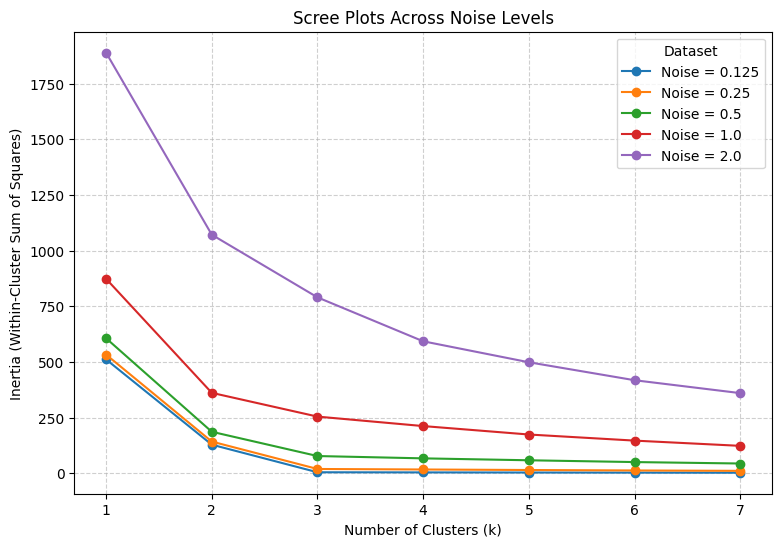

In [10]:
#Q1.1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


#Q1.2


#As the overall noise parameters have a tendency to increase from 0.125 to 2.0, this  will cause the overall visual distinctness to decrease and cause an overlapping effect.


datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (name, df) in enumerate(datasets.items()):
    ax = axes[i]

    for group in ['a', 'b', 'c']:
        subset = df[df['group'] == group]
        ax.scatter(subset['x1'], subset['x2'], label=group, alpha=0.7, s=25)

    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_title(name)
    ax.legend(title='Group')

axes[5].set_visible(False)

plt.tight_layout()
plt.show()


#Q1.3

#High levels of noise effects ones ability to not witness any random variation and overlap between data points.
# Noise does not have clear natural groupinfs, so inflation of the variance is a result at higher cluster counts.
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}

k_range = range(1, 8)
plt.figure(figsize=(9, 6))

for name, df in datasets.items():
    X = df[['x1', 'x2']]

    inertias = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)

    plt.plot(k_range, inertias, marker='o', label=name)

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Scree Plots Across Noise Levels')
plt.legend(title='Dataset')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



#Q1.4

#Intuition of the elbow, is  essentially structured on the backbone of error reduction and model complexiity, where an increase of number of clusters results in error decreasing because data points get scattered in get closer to their assignments
#A sharp drop essentially shows how clusters being added to the






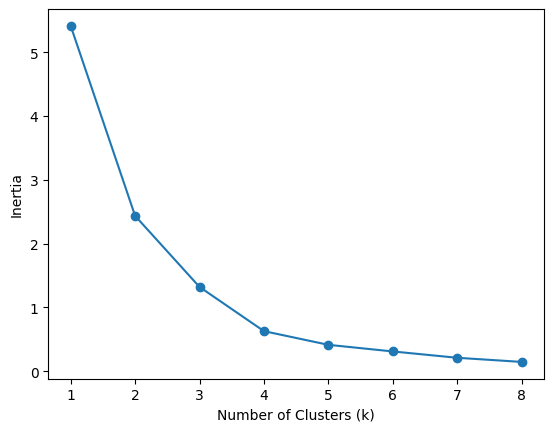

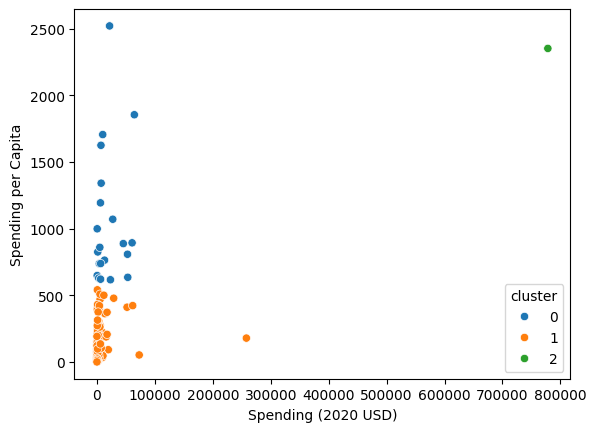

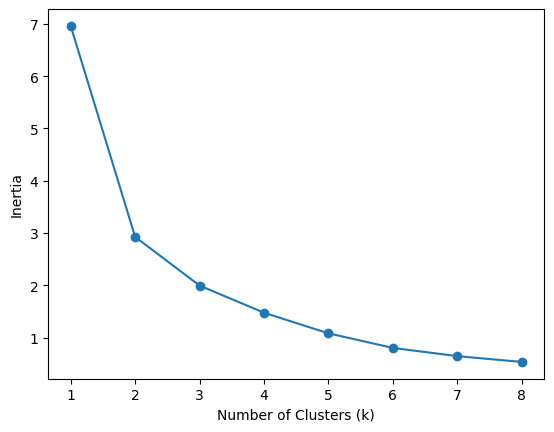

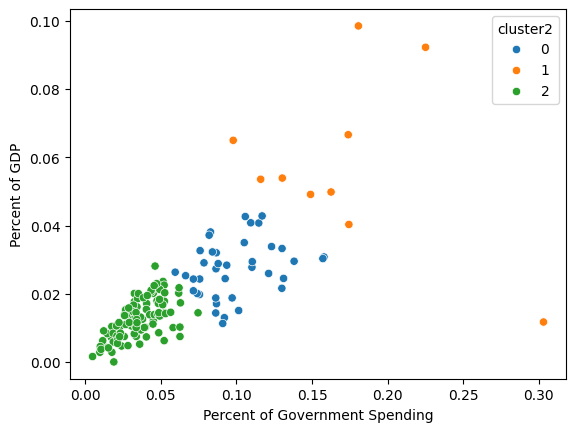

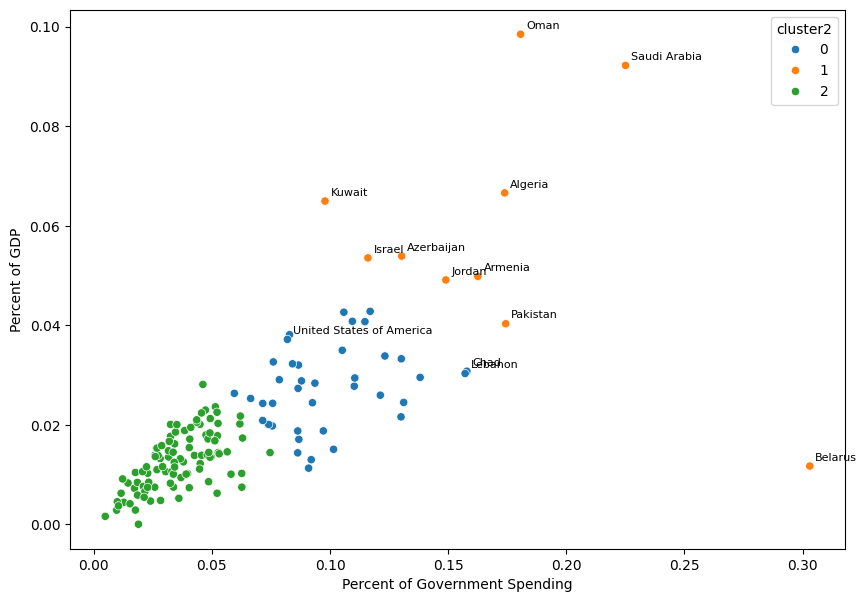

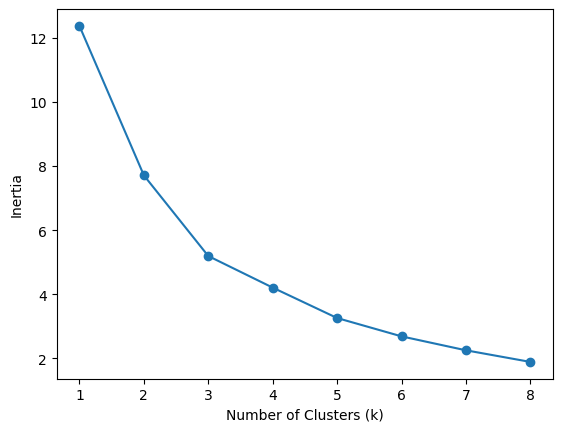

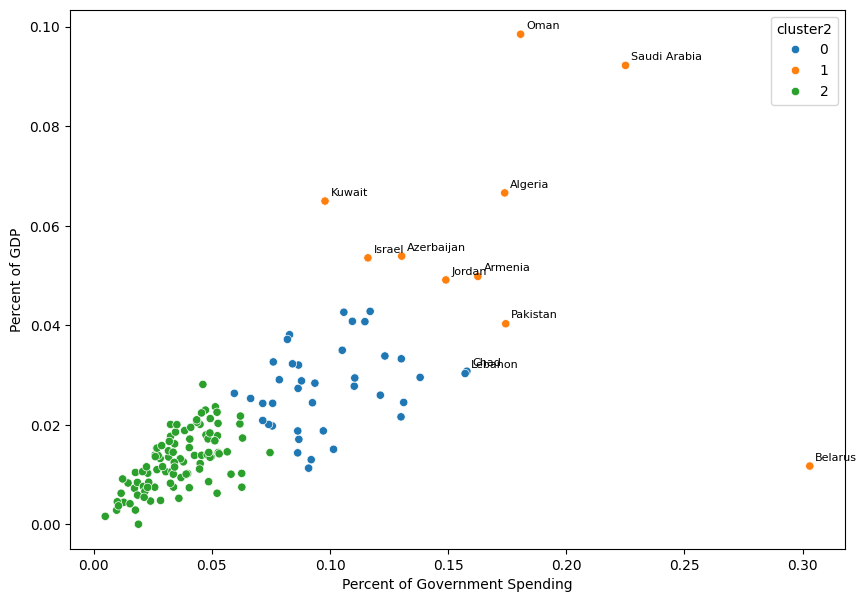

In [11]:

#Q2.1

import pandas as pd
url = "./data/SIPRI Military Expenditure Database.csv"
df = pd.read_csv(url)

df = df[df['Year'] == 2020].dropna()
df = df.drop(columns=['index', 'Year']).set_index('Country')

#After dropping rows with missing values and only taking values at 2020, I also noticed index and yeat can be dropped because neither are real variables.
#Also made country a row label moving out of features.

#Q2.2

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

cols = ['Spending (2020 USD)', 'Spending per Capita']

# min-max normalize
X = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())

# scree plot
ks = range(1, 9)
inertias = [KMeans(k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
plt.plot(ks, inertias, marker='o')
plt.xlabel('Number of Clusters (k)'); plt.ylabel('Inertia')
plt.show()

km = KMeans(3, n_init=10, random_state=0).fit(X)
df['cluster'] = km.labels_

# scatter plot
sns.scatterplot(data=df, x=cols[0], y=cols[1], hue='cluster', palette='tab10')
plt.show()

df.groupby('cluster')[cols].describe()

df.loc['United States of America']

def labeled_scatter(df, xcol, ycol, cluster_col, extra=None, n=8):
    plt.figure(figsize=(10, 7))
    sns.scatterplot(data=df, x=xcol, y=ycol, hue=cluster_col, palette='tab10')

    names = set(df.nlargest(n, xcol).index) | set(df.nlargest(n, ycol).index)
    names |= set(extra or [])

    for name in names:
        plt.annotate(name, (df.loc[name, xcol], df.loc[name, ycol]),
                     xytext=(4, 4), textcoords='offset points', fontsize=8)
    plt.show()

#I see as K equal 3 that the cluster is put into the more bigg spenders, the rest of the pack, and the united states isolated on its own level
#The US is alone because its total spending is levels above any other country, the gap between US  (second largest) is rather substantial
#Patterns noticed: Per capita is key indicator of seperation between rich and high spendingg countries
#Pattern of cluster sizes are rather unbalances as the majority of countries are in one cluster with the US being in a league of their own.


#Q2.3

cols2 = ['Percent of Government Spending', 'Percent of GDP']
X2 = (df[cols2] - df[cols2].min()) / (df[cols2].max() - df[cols2].min())

ks = range(1, 9)
inertias = [KMeans(k, n_init=10, random_state=0).fit(X2).inertia_ for k in ks]
plt.plot(ks, inertias, marker='o')
plt.xlabel('Number of Clusters (k)'); plt.ylabel('Inertia')
plt.show()

km2 = KMeans(3, n_init=10, random_state=0).fit(X2)
df['cluster2'] = km2.labels_

sns.scatterplot(data=df, x=cols2[0], y=cols2[1], hue='cluster2', palette='tab10')
plt.show()

df.groupby('cluster2')[cols2].describe()
df.loc['United States of America', 'cluster2']

labeled_scatter(df, cols2[0], cols2[1], 'cluster2',
                extra=['United States of America'])

#It seems like now the US is not an outlier, but now it is in the middle cluster
#Clusters have more balances versus the lopsided numbers in previous distribution
#Different set of countries stand out for different reasons such as conflict and military expenses

#Q2.4

cols4 = ['Spending (2020 USD)', 'Spending per Capita',
         'Percent of Government Spending', 'Percent of GDP']
X4 = (df[cols4] - df[cols4].min()) / (df[cols4].max() - df[cols4].min())

ks = range(1, 9)
inertias = [KMeans(k, n_init=10, random_state=0).fit(X4).inertia_ for k in ks]
plt.plot(ks, inertias, marker='o')
plt.xlabel('Number of Clusters (k)'); plt.ylabel('Inertia')
plt.show()

km4 = KMeans(3, n_init=10, random_state=0).fit(X4)
df['cluster4'] = km4.labels_

df.groupby('cluster4')[cols4].mean()
df['cluster4'].value_counts()
df.loc['United States of America', 'cluster4']

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x=cols2[0], y=cols2[1], hue='cluster2', palette='tab10')

extreme = pd.concat([
    df.nlargest(8, cols2[0]),
    df.nlargest(8, cols2[1]),
]).drop_duplicates()

for name, row in extreme.iterrows():
    plt.annotate(name, (row[cols2[0]], row[cols2[1]]),
                 xytext=(4, 4), textcoords='offset points', fontsize=8)

plt.show()

#In comparison with above, the US is back in a cluster with other countries. Grouped with countries that have high numbers in the two metrics being measured above.
#Seems like the clusters as a whole now mix the two metrics above. Some countries where one metric outweighs the other will cause a drop.
#Q2.5
#Helpful based on what variables were being assessed and utilized, like dollar variables or percent variables allowing for real structure to follow through.
#Limitations came when tackling outliers like US.

\- **Phase 1 commit SHA ID:** e3bd2b4d0315fef961a09f2c109eb4e4b1a13d27
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

here is my phase 1 question 1 work, please come up with a list of concise suggestions, only 5 suggestions i can fix

numbered list via markdown

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. **Add `import matplotlib.pyplot as plt` before the Q1.2 plotting code.** `plt` is currently only imported in the Q1.3 cell, so running top to bottom gives a `NameError`. Put the import in the Q1.1 cell.

2. **Make the Q1.2 written answer specific.** Say that at noise 0.125 and 0.25 the three groups are tight and clearly separated, at 0.5 the edges start to touch, at 1.0 they overlap heavily, and at 2.0 they merge into one blob. Add `sharex=True, sharey=True` to `plt.subplots` so the growing spread is visible across panels.

3. **Rewrite the Q1.3 explanation and drop the incorrect "inflation of the variance" line.** Use the actual numbers: at 0.125 inertia falls 512 → 129 → 5 and then flattens (clear elbow at k=3); at 0.5 it falls 607 → 187 → 78 (softer elbow); at 1.0 and 2.0 it declines steadily (2.0: 1889 → 1072 → 791 → 593), so there is no clear elbow and k can't be picked definitively. Also note that overall inertia is higher with more noise.

4. **Make the low-noise scree curves readable in Q1.3.** On one shared axis the 0.125 and 0.25 curves look flat next to the 2.0 curve. Use `plt.yscale('log')` or one subplot per dataset, and state which k you would choose for each noise level.

5. **Finish Q1.4 and tie it to the simulation.** The comment ends mid-sentence ("...clusters being added to the"). Explain that the true structure is 3 groups, so going from k=1 to k=3 removes the large between-group distance (big inertia drop), while beyond k=3 you only split noise within a group (small, diminishing drops). That change in slope is the elbow. Also fix typos such as "groupinfs" and the unclear "witness any random variation" phrase in Q1.3.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Import `plt` before Q1.2 | Accept | `plt` is first imported in the Q1.3 cell. Verified by Restart and run all. |
| 2. Specific Q1.2 description and shared axes | Modify | Keep shared axes, but write the description from what the five plots actually show. |
| 3. Rewrite Q1.3 using inertia values | Modify | Reran KMeans: the elbow at k=3 is sharp at 0.125 and softer at 0.5, and 2.0 has none. Noise 1.0 is ambiguous, not "no elbow". |
| 4. Log scale for scree plots | Modify | Keep one canvas (allowed) and add `plt.yscale('log')`. Verified by replotting. |
| 5. Finish Q1.4 | Accept | The comment was cut off. At 0.125, k=1 to 3 drops inertia by about 507, but k=3 to 7 only by about 2. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

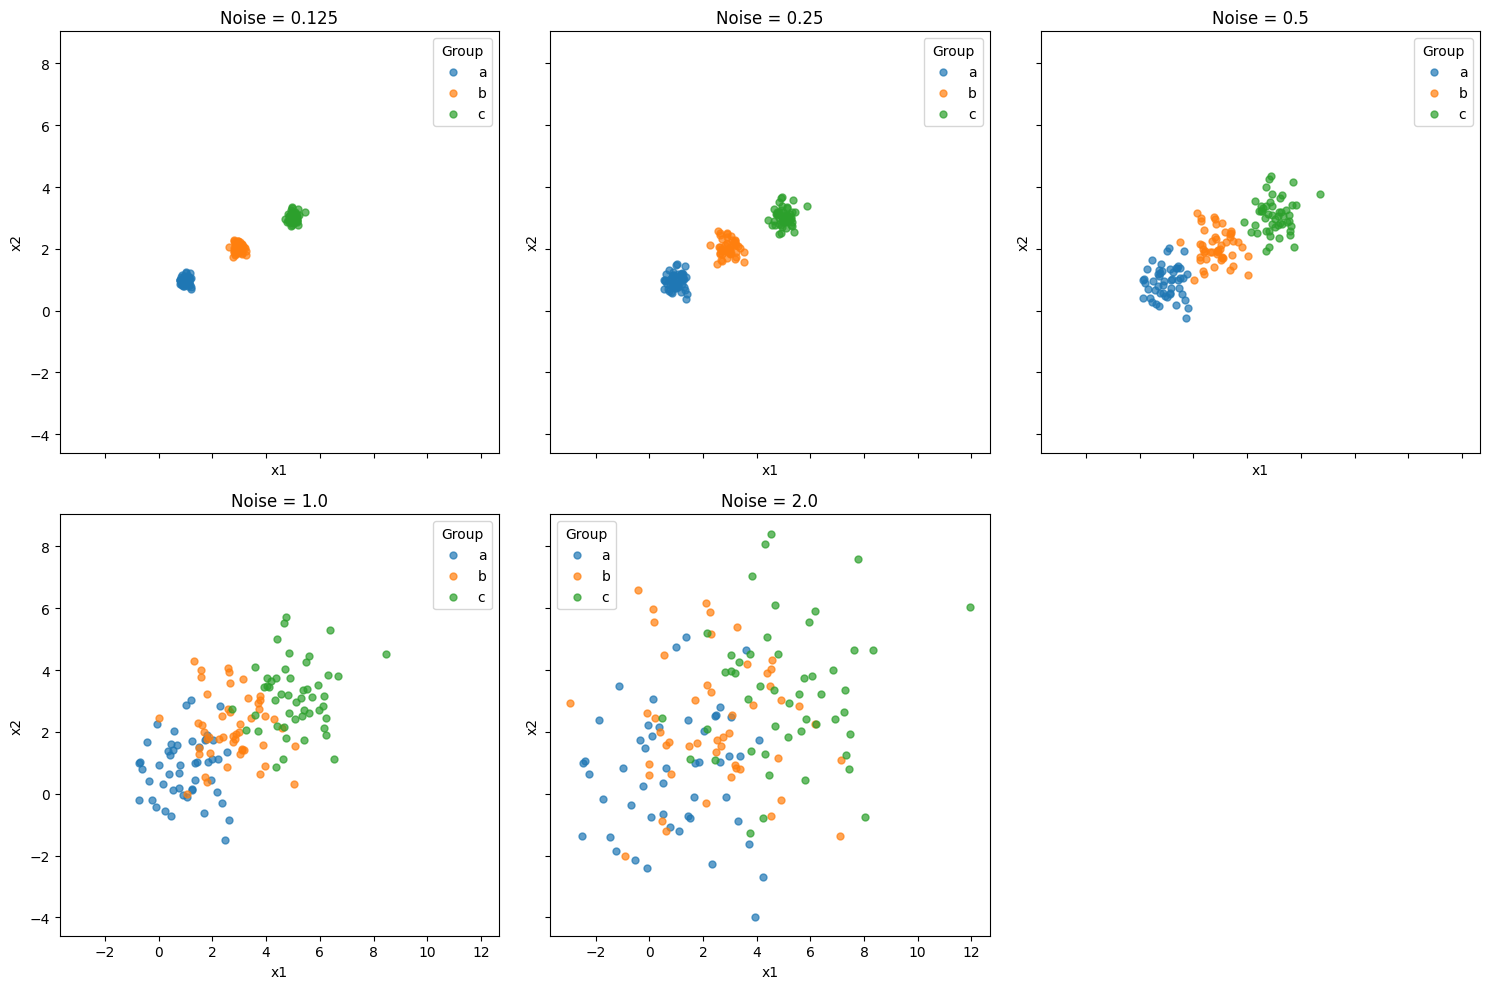

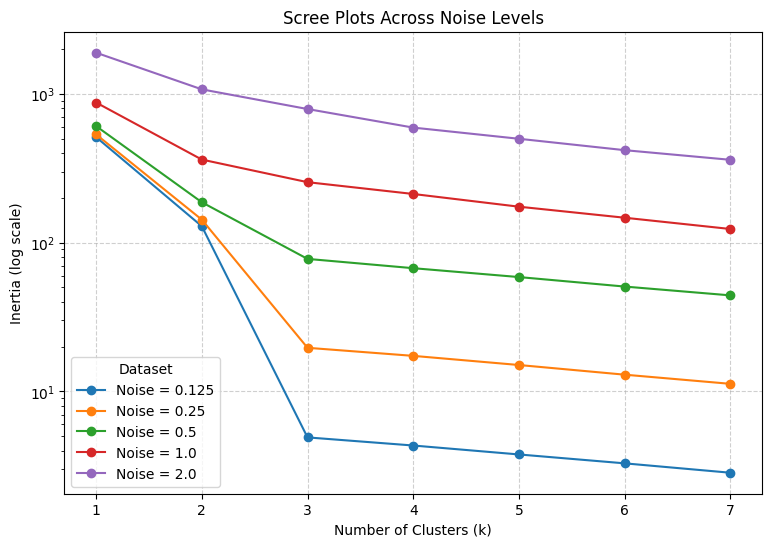

In [12]:
# Your Phase 2 solution to the problem goes here.
#Q1.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100)  # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N), np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N), np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N), np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:], 'x2':X1[1,:], 'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:], 'x2':X2[1,:], 'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:], 'x2':X3[1,:], 'group':'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}


#Q1.2
fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (name, data) in zip(axes, datasets.items()):
    for group in ['a', 'b', 'c']:
        subset = data[data['group'] == group]
        ax.scatter(subset['x1'], subset['x2'], label=group, alpha=0.7, s=25)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_title(name)
    ax.legend(title='Group')

axes[5].set_visible(False)
plt.tight_layout()
plt.show()

# At 0.125 and 0.25 the three groups are tight and clearly separated.
# At 0.5 the groups are still identifiable, but a, b and c start to touch at the edges.
# At 1.0 the groups overlap heavily, and only the rough left-to-right ordering remains.
# At 2.0 the groups are mixed into one cloud, and group labels can't be seen visually.
# So as noise increases, visual distinctness decreases.


#Q1.3
k_range = range(1, 8)
plt.figure(figsize=(9, 6))

for name, data in datasets.items():
    X = data[['x1', 'x2']]
    inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_
                for k in k_range]
    plt.plot(k_range, inertias, marker='o', label=name)

plt.yscale('log')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (log scale)')
plt.title('Scree Plots Across Noise Levels')
plt.legend(title='Dataset')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Overall inertia rises with noise, since points sit farther from their centers.
# Noise 0.125: inertia drops from about 512 to 129 to 5, then flattens, so
#   there is a sharp elbow at k=3 and I can pick k=3 with confidence.
# Noise 0.25 and 0.5: the elbow at k=3 is still visible but gets softer
#   (0.5: 607 -> 187 -> 78), so k=3 is still a reasonable choice.
# Noise 1.0: the bend at k=2-3 is weak, so the choice of k is ambiguous.
# Noise 2.0: inertia falls steadily with no elbow, so I can't definitively pick k.
# The log scale makes the low-noise elbows visible next to the high-noise curves.


#Q1.4
# The elbow is the point where adding another cluster stops reducing error much.
# More clusters always lowers inertia, because points get closer to their centers.
# In this simulation the data has 3 true groups. Going from k=1 to k=3 removes the
# large distance between groups, so inertia drops sharply (at noise 0.125,
# about 512 to 5). Beyond k=3, extra clusters only split noise within a group,
# so the drops are tiny (about 5 to 3 from k=3 to 7). That change in slope is the
# elbow. As noise grows, groups overlap, the between-group gain shrinks, and the
# elbow disappears.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

Majority of the fixes consisted of minute, miniature, miniscule, changes in terms imports and other explanations I could have dove deeper and elaborated on more thoroughly. Using Claude, it is a common theme to really extract and find what needs to be changed and I believe it did that to its fullest capacity to maximize the overall quality and depth of my paper as a whole. In terms of making my answers more specific and accurate, it fished out areas of improvement and suggested the right call each time. Some limitations were that it made some answers a little extra such as making curves more readable and things of that nature which do not really affect the result too too too much. It was verified through going back and looking at main objectives and then precisely following up with how I went about solving versus the final AI version which filled in the gaps of what I missed out on in my own solution.


###Question 2 Prompt:

Follow the same structure for me for my question 2

### AI-proposed changes

1. **Fix the Q2.4 scatter plot.** It plots `cluster2` on the percent variables, which are the part 3 clusters. Color by `cluster4` instead. Four variables can't be plotted at once, so use the two dollar variables as axes.

2. **Use `labeled_scatter` in all three parts and define it once at the top.** It is defined in Q2.2 but never called there, and Q2.2 and Q2.4 use unlabeled plots, so the US and other countries can't be identified.

3. **Justify each choice of k with the scree values.** Add a comment per part: part 2 elbow at k=3 (5.41 → 2.44 → 1.32 → 0.63), part 3 weaker elbow (6.96 → 2.93 → 2.00 → 1.48), part 4 ambiguous between 3 and 4 (7.71 → 5.19 → 4.21). Add plot titles.

4. **Add specifics to the written answers in Q2.2-Q2.4.** Include cluster sizes, typical values, and example countries (e.g., part 2: 21 / 126 / 1 countries, US at about $778,000M versus about $258,000M for China).

5. **Strengthen Q2.1 and Q2.5 and fix typos.** Q2.1 should mention the mixed units and scales (so scaling is needed) and the right skew. Q2.5 should list limitations (US outlier, unbalanced clusters, weak elbows, no explanation of causes). Fix "yeat", "bigg", "seperation", "spendingg", "unbalances".

Evaluation of AI suggestions

| Change | Decision | Reason and verification |
|---|---|---|
| 1. Fix Q2.4 scatter to use `cluster4` | Accept | The original plotted `cluster2`, which was a real bug.|
| 2. Label points in all parts, define the function once | Accept | The function was already in the notebook but not used in Q2.2 or Q2.4. Verified that labels show the US and the other extremes. |
| 3. Justify k with scree values | Modify | Reran scree values: 5.41 → 2.44 → 1.32 for part 2, 6.96 → 2.93 → 2.00 for part 3, and 12.37 → 7.71 → 5.19 → 4.21 for part 4. I kept k=3 for part 4 for consistency but said that k=4 is also reasonable. |
| 4. Add specifics to the written answers | Accept | The numbers come from  `.groupby` and `value_counts` output, |
| 5. Strengthen Q2.1 and Q2.5, fix typos | Accept | Min and max values confirm the scale differences (about 0.0001 to 778,000), and the typos are visible in the notebook. |

AI-assisted solution in full

(148, 4)


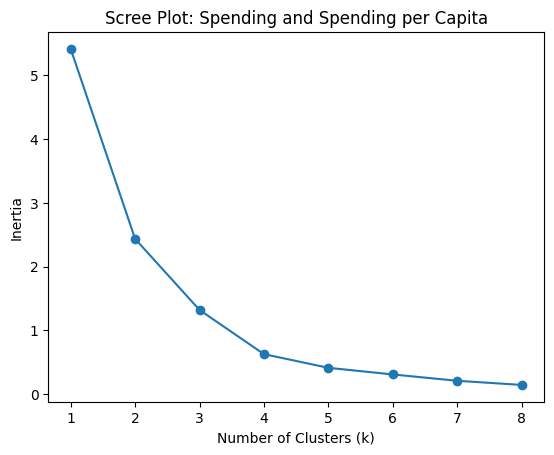

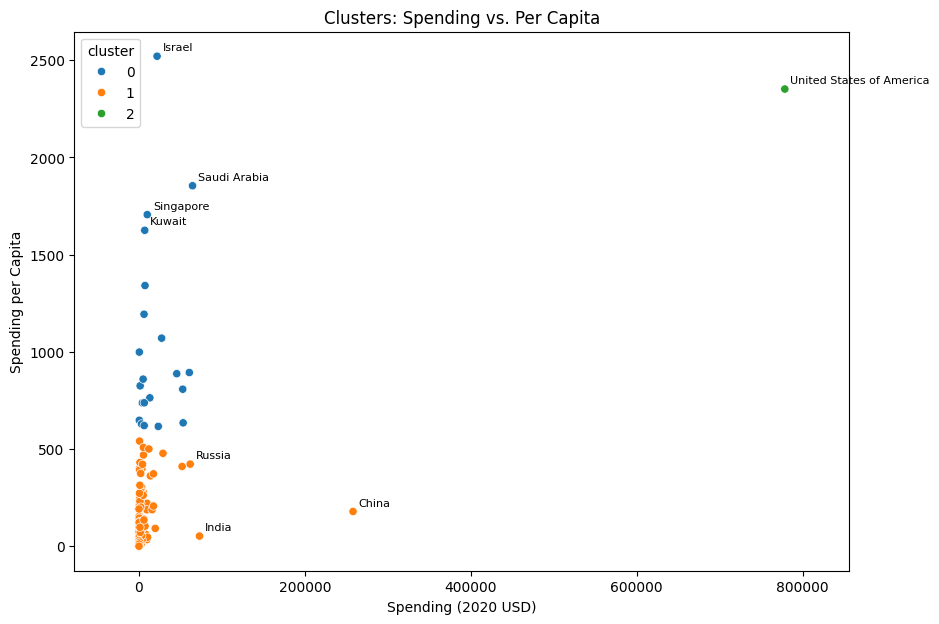

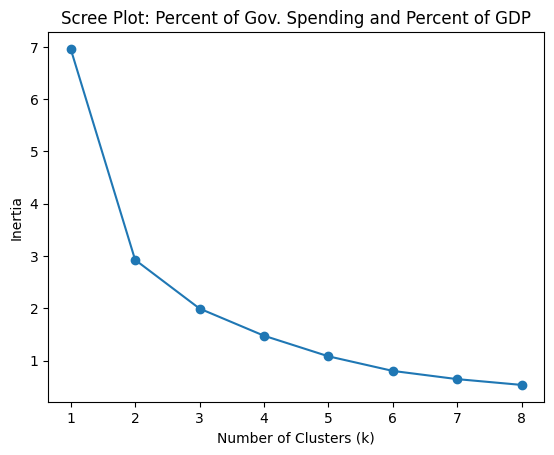

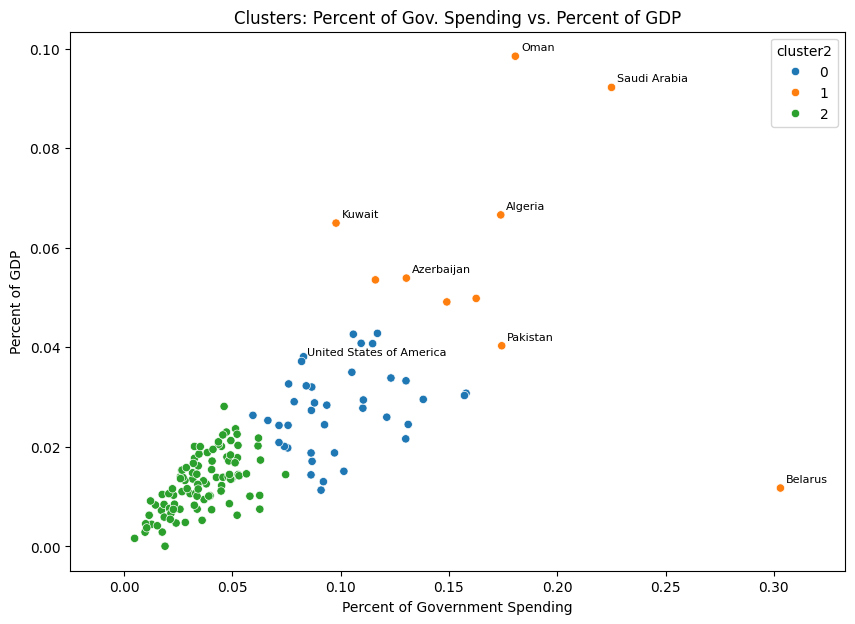

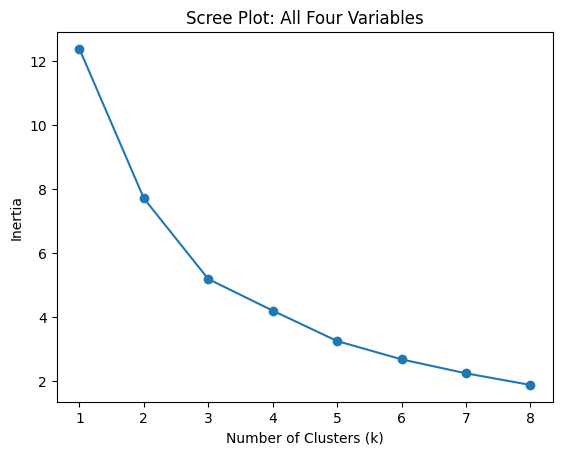

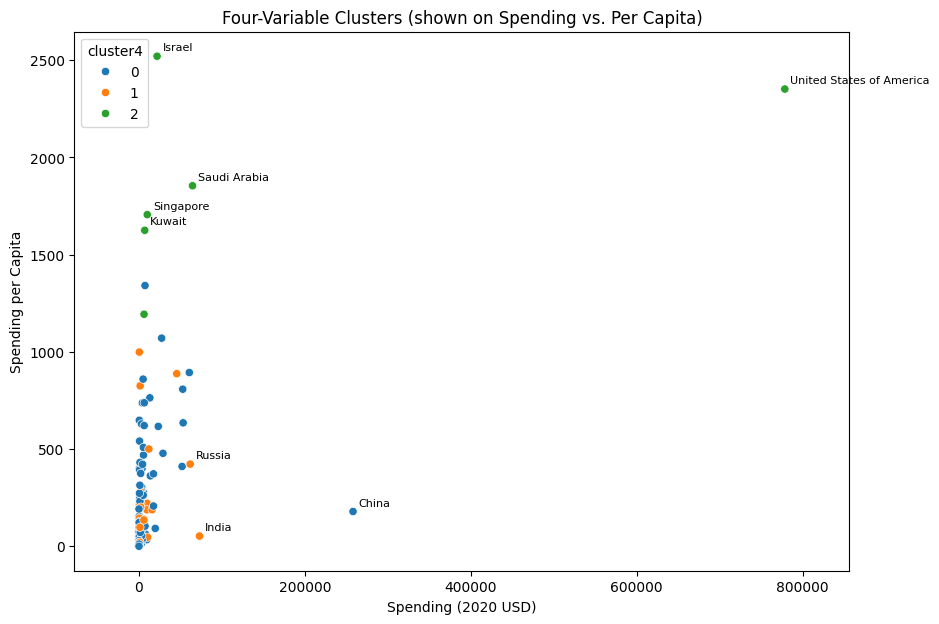

In [13]:
#Q2.1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

url = "./data/SIPRI Military Expenditure Database.csv"
df = pd.read_csv(url)

df = df[df['Year'] == 2020].dropna()
df = df.drop(columns=['index', 'Year']).set_index('Country')
print(df.shape)  # (148, 4)

# Further cleaning: `index` is a row counter and `Year` is constant after filtering,
# so neither is a real variable. `Country` is a label, so it is the row index and
# not a feature. The four numeric variables are on very different scales (dollars in
# millions, per capita in dollars, and two fractions below 1) and are right-skewed,
# so they need to be normalized before running k-means.


# Helper functions
def minmax(data, columns):
    return (data[columns] - data[columns].min()) / (data[columns].max() - data[columns].min())

def scree(X, title):
    ks = range(1, 9)
    inertias = [KMeans(k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    plt.plot(ks, inertias, marker='o')
    plt.title(title)
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Inertia')
    plt.show()

def labeled_scatter(data, xcol, ycol, cluster_col, extra=None, n=5, title=''):
    plt.figure(figsize=(10, 7))
    sns.scatterplot(data=data, x=xcol, y=ycol, hue=cluster_col, palette='tab10')
    names = set(data.nlargest(n, xcol).index) | set(data.nlargest(n, ycol).index)
    names |= set(extra or [])
    for name in names:
        plt.annotate(name, (data.loc[name, xcol], data.loc[name, ycol]),
                     xytext=(4, 4), textcoords='offset points', fontsize=8)
    plt.margins(x=0.1)
    plt.title(title)
    plt.show()

US = ['United States of America']


#Q2.2
cols = ['Spending (2020 USD)', 'Spending per Capita']
X = minmax(df, cols)

scree(X, 'Scree Plot: Spending and Spending per Capita')

km = KMeans(3, n_init=10, random_state=0).fit(X)
df['cluster'] = km.labels_

labeled_scatter(df, cols[0], cols[1], 'cluster', extra=US,
                title='Clusters: Spending vs. Per Capita')

df.groupby('cluster')[cols].describe()
df.loc['United States of America']

# k=3: inertia falls sharply from 5.41 to 2.44 to 1.32, then only slowly (0.63 at k=4).
# The clusters are: 21 big, rich spenders (e.g., Saudi Arabia, UK, Germany, France, Israel,
# with mean per capita of about $1,046), 126 other countries (including China, India,
# Russia, Japan, with mean per capita of about $122), and the US alone.
# The US is alone because its spending of about $778,000M is about 3x the next largest
# (China, about $258,000M), so it is far from every other point.
# Per capita separates the rich countries from the rest: China and India spend a lot in
# total, but little per person, so they are in the large cluster.
# The clusters are very unbalanced because the US outlier compresses everyone else
# near 0 after min-max normalization.


#Q2.3
cols2 = ['Percent of Government Spending', 'Percent of GDP']
X2 = minmax(df, cols2)

scree(X2, 'Scree Plot: Percent of Gov. Spending and Percent of GDP')

km2 = KMeans(3, n_init=10, random_state=0).fit(X2)
df['cluster2'] = km2.labels_

labeled_scatter(df, cols2[0], cols2[1], 'cluster2', extra=US,
                title='Clusters: Percent of Gov. Spending vs. Percent of GDP')

df.groupby('cluster2')[cols2].describe()
df.loc['United States of America', 'cluster2']

# k=3: the elbow is weaker (6.96, 2.93, 2.00, 1.48), but k=3 is still reasonable.
# The clusters are 10 high-burden countries (e.g., Oman, Saudi Arabia, Kuwait, Israel,
# about 17% of gov. spending), 39 medium countries (including the US, Russia, Colombia)
# and 99 low-burden countries (e.g., most of Europe, about 3.6%).
# Compared to part 2, the US is no longer an outlier (it is in the middle cluster),
# and the clusters are more balanced (10 / 39 / 99 versus 1 / 21 / 126).
# Part 2 separated countries by scale and wealth, and part 3 separates them by
# how much of their economy and budget goes to the military.


#Q2.4
cols4 = ['Spending (2020 USD)', 'Spending per Capita',
         'Percent of Government Spending', 'Percent of GDP']
X4 = minmax(df, cols4)

scree(X4, 'Scree Plot: All Four Variables')

km4 = KMeans(3, n_init=10, random_state=0).fit(X4)
df['cluster4'] = km4.labels_

df.groupby('cluster4')[cols4].mean()
df['cluster4'].value_counts()
df.loc['United States of America', 'cluster4']

# Four variables can't be plotted at once, so the axes are the two dollar variables
# and the colors are the four-variable clusters.
labeled_scatter(df, cols[0], cols[1], 'cluster4', extra=US,
                title='Four-Variable Clusters (shown on Spending vs. Per Capita)')

# k=3: the elbow is weak (7.71, 5.19, 4.21, 3.26), so k=3 or 4 are both defensible.
# I used k=3 for consistency with parts 2 and 3.
# The clusters are 6 high-everything countries (the US, Saudi Arabia, Israel,
# Singapore, Kuwait, Oman), 31 countries with a high burden but moderate size (India,
# Russia, South Korea, Iran, Pakistan), and 111 low-burden countries (China, UK,
# Germany, France, Japan).
# Compared to parts 2 and 3, the US is back in a group with others, but a small one
# of countries with high per capita and high share of GDP. China moves to the low-burden
# group, because its low per capita and share of GDP outweigh its large total.
# The result mixes both earlier views: scale and burden.


#Q2.5
# Yes, k-means found useful patterns, but they depended on which variables were used.
# Dollar variables separated countries by scale and wealth (the US alone, and rich
# countries with high per capita). Percent variables separated them by military burden
# (mostly Gulf and Middle East states at the top). Using all four variables combined
# both views.
# Limitations: the US outlier compressed the min-max scale and made clusters very
# unbalanced (a log transform or standardization may help), the elbows were weak in
# parts 3 and 4, so the choice of k was partly subjective, and the clusters describe
# patterns but do not explain why countries spend what they do.

### *Reflection on AI assistance
In your own words without generative AI.




[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

Majority of the fixes were to the different intricacies found in the execution and overall outcome of how each plot was dialed up and eventually executed in relation to the overall information given. Labels were fixed and added to help overall assessment and evaluation of how each plot can be labeled to determine differences between each value in terms of location and representation in respect to respective values that they were precisely tied to. Other fixes and changes included typos and other clearing up of how content was written, similar to Question One final product.Some limitations included its strength which was sometimes overstepping the exact amount of changes needed overall for each change. Claude continues to prove that it is the best AI when working with Python in terms of being able to formulate concise and intuitive plots and frames in respect to the given files and information that it immediately has at its disposal